# 10a · Linha de base de custo e consolidação do pipeline de economias
**Pergunta:** quanto custa cada pedido, linha e palete do SDC hoje, e quanto o programa de redução de
custos pode economizar de verdade, **somando as fases 4 a 9 sem contar nada duas vezes**?

Três cuidados deste notebook:
1. **Escalas diferentes.** A Fase 5 está em escala 10%; as fases 6–9, em escala cheia. Tudo aqui fica em
   **escala cheia** e a **custo de hora paga** (mesmo critério do custeio da Fase 8).
2. **Dupla contagem.** O slotting aparece nas fases 5, 6, 7 e 8, e o carrinho do e-commerce nas fases 7 e 8.
   Cada ganho entra **uma vez**, e o efeito combinado slotting + carrinho é recalculado junto.
3. **Perdas de frio em duas visões** (decisão do John): "como nos dados" e "ajustada ao mercado"
   (premissa em `config/cost_program.yaml`). A priorização usa a visão ajustada, que é a conservadora.

Ano-base nov/2025–out/2026. Valores em R$ são **estimativas de ordem de grandeza**. Nada nos dados
originais nem no `savings_register.csv` é alterado: o resultado consolidado vai para `reports/phase10/`.

*EN summary: full-scale cost baseline (cost per order, line and pallet), cold-loss "as in data" vs
"market-adjusted" views, and a de-duplicated savings pipeline built from the Phase 5–9 register.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import flowsim as fs
from dcanalysis import q, save, savefig, log, params, ROOT, SAVINGS

NB = "10a"
PH8, PH9, PH10 = (ROOT / "reports" / f"phase{n}" for n in (8, 9, 10))
P = params(); prm = fs.carregar_parametros(); slot = fs.carregar_slotting()
CP = yaml.safe_load(open(ROOT / "config" / "cost_program.yaml", encoding="utf-8"))
C = P["costs"]
INI, FIM = C["base_year"]
K = prm["scale"]                                   # 10: dados em escala 10% -> escala cheia
# Hora-padrão -> hora PAGA (ocupação de 85% e 5% de faltas), igual às Fases 7 e 8
FATOR_PAGO = 1 / (P["labor"]["utilization_target"] * (1 - P["labor"]["absenteeism"]))
c_op = P["labor_cost"]["picker_brl_h"] * FATOR_PAGO
c_ret = P["labor_cost"]["reach_truck_brl_h"] * FATOR_PAGO
ZONAS = ["dry", "chilled", "frozen"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
print(f"Escala x{K} | fator de hora paga {FATOR_PAGO:.3f}")

Escala x10 | fator de hora paga 1.238


## 1. Linha de base: custo por pedido, por linha e por palete
O custo total vem do custeio por atividade da Fase 8 (`08a_custo_servir_canal_zona.csv`). Aqui ele é
dividido pelos **direcionadores** de volume: pedidos, linhas, unidades, paletes recebidos e paletes
expedidos (palete-equivalente = unidades ÷ unidades por palete).

In [2]:
cts = pd.read_csv(PH8 / "08a_custo_servir_canal_zona.csv", sep=";", decimal=",").set_index(["channel", "zone"])
vol = q("""SELECT f.channel, s.zone, COUNT(*) AS linhas, COUNT(DISTINCT f.order_id) AS pedidos,
                  SUM(f.qty_picked_units) AS unidades, SUM(f.qty_picked_units * s.unit_price) AS receita,
                  SUM(1.0 * f.qty_picked_units / (s.units_per_case * s.cases_per_pallet)) AS paletes_exp
           FROM fact_order_line f JOIN dim_sku s ON s.sku_id = f.sku_id
           WHERE f.order_date >= :i AND f.order_date < :f GROUP BY 1, 2""", i=INI, f=FIM).set_index(["channel", "zone"]) * K
ped_canal = q("""SELECT channel, COUNT(DISTINCT order_id) AS pedidos FROM fact_order_line
                 WHERE order_date >= :i AND order_date < :f GROUP BY 1""", i=INI, f=FIM).set_index("channel").pedidos * K
rec = q("""SELECT zone, COUNT(*) AS paletes_rec FROM fact_receipt
           WHERE arrival_ts >= :i AND arrival_ts < :f GROUP BY zone""", i=INI, f=FIM).set_index("zone").paletes_rec * K

total_base = cts.total.sum()
print(f"Custo total da linha de base: R$ {total_base / 1e6:,.1f} mi/ano (confere com a Fase 8: R$ 96,7 mi)")


def unitarios(custo_cz):
    """Indicadores unitários por canal e no total, a partir de um custo por canal x zona."""
    linhas = []
    for canal in ["B2B", "ECOM", "Total"]:
        sel = custo_cz if canal == "Total" else custo_cz.xs(canal, level="channel", drop_level=False)
        v = vol if canal == "Total" else vol.xs(canal, level="channel", drop_level=False)
        ped = ped_canal.sum() if canal == "Total" else ped_canal[canal]
        linhas.append({"canal": canal, "custo_mi": sel.sum() / 1e6, "pedidos": ped, "por_pedido": sel.sum() / ped,
                       "por_linha": sel.sum() / v.linhas.sum(), "por_unidade": sel.sum() / v.unidades.sum(),
                       "por_palete_expedido": sel.sum() / v.paletes_exp.sum(),
                       "pct_receita": 100 * sel.sum() / v.receita.sum()})
    return pd.DataFrame(linhas).set_index("canal")


base_dados = unitarios(cts.total)
# Custo por palete recebido (só no total: o recebimento é da zona, não do canal)
print("Custo do CD por palete recebido: R$ {:,.0f}".format(total_base / rec.sum()))
base_dados.round(2)

Custo total da linha de base: R$ 96.7 mi/ano (confere com a Fase 8: R$ 96,7 mi)
Custo do CD por palete recebido: R$ 181


,custo_mi,pedidos,por_pedido,por_linha,por_unidade,por_palete_expedido,pct_receita
canal,,,,,,,
B2B,92.85,186170,498.71,15.57,0.36,332.97,3.39
ECOM,3.82,459110,8.32,2.08,1.87,"1,227.66",16.66
Total,96.66,645280,149.80,12.40,0.37,342.84,3.50


**Leitura:** um pedido B2B (loja) custa ~R$ 500 e um de e-commerce ~R$ 8. Mas, **por unidade**, o
e-commerce custa ~5× mais, porque cada pedido tem poucas unidades. Essa é a base para acompanhar o
programa: **custo por pedido, por linha e por unidade**, por canal.

## 2. Perdas de frio em duas visões
As baixas por cadeia do frio dos dados equivalem a 2,6% (resfriado) e 8,1% (congelado) da receita da zona,
bem acima do que se espera de uma operação madura. A visão **ajustada ao mercado** rebaixa a perda por
frio para a % da receita definida em `config/cost_program.yaml` (premissa estimada, não dado de fonte).
A proporção entre **evento** (falha de jan/2026) e **perda crônica** é mantida.

In [3]:
frio = q("""SELECT s.zone, m.date_key BETWEEN '2026-01-06' AND '2026-01-18' AS evento,
                   SUM(m.qty_units * s.unit_cost) AS custo
            FROM fact_movement m JOIN dim_sku s ON s.sku_id = m.sku_id
            WHERE m.movement_type = 'WRITE_OFF_COLD_CHAIN' AND m.date_key >= :i AND m.date_key < :f
            GROUP BY 1, 2""", i=INI, f=FIM)
frio = frio.pivot_table(index="zone", columns="evento", values="custo", aggfunc="sum").fillna(0) * K
frio.columns = ["cronica", "evento"]
frio["total"] = frio.cronica + frio.evento
receita_zona = vol.receita.groupby(level="zone").sum()
mercado = pd.Series(CP["market_cold_chain_loss_pct_revenue"])
visoes = pd.DataFrame({
    "receita_mi": receita_zona.reindex(frio.index) / 1e6,
    "frio_dados_mi": frio.total / 1e6,
    "frio_dados_pct": 100 * frio.total / receita_zona.reindex(frio.index),
    "frio_mercado_pct": mercado.reindex(frio.index),
})
visoes["frio_mercado_mi"] = visoes.receita_mi * visoes.frio_mercado_pct / 100
visoes["fator_ajuste"] = visoes.frio_mercado_mi / visoes.frio_dados_mi
visoes["cronica_dados_mi"] = frio.cronica / 1e6
visoes["cronica_mercado_mi"] = visoes.cronica_dados_mi * visoes.fator_ajuste
visoes.loc["Total"] = visoes.sum()
visoes.loc["Total", ["frio_dados_pct", "frio_mercado_pct", "fator_ajuste"]] = np.nan
save(visoes.reset_index(names="zona").round(3), "10a_perdas_frio_visoes", out=PH10)
visoes.round(2)

,receita_mi,frio_dados_mi,frio_dados_pct,frio_mercado_pct,frio_mercado_mi,fator_ajuste,cronica_dados_mi,cronica_mercado_mi
zone,,,,,,,,
chilled,947.21,22.65,2.39,1.00,9.47,0.42,10.58,4.42
frozen,413.86,33.36,8.06,1.00,4.14,0.12,24.76,3.07
Total,"1,361.07",56.02,NaN,NaN,13.61,NaN,35.34,7.49


In [4]:
# Linha de base na visão de mercado: o custo cai só na parcela "perdas" do frio, rateada como na Fase 8 (por unidades)
reducao_zona = (frio.total - visoes.loc[frio.index, "frio_mercado_mi"] * 1e6)
share_und = vol.unidades / vol.unidades.groupby(level="zone").transform("sum")
reducao_cz = share_und * vol.index.get_level_values("zone").map(reducao_zona).fillna(0).values
base_mercado = unitarios(cts.total - reducao_cz)
comparacao = pd.concat({"dados": base_dados, "mercado": base_mercado}, axis=1)
save(comparacao.reset_index().round(3), "10a_linha_base", out=PH10)
comparacao[[("dados", "custo_mi"), ("mercado", "custo_mi"), ("dados", "por_pedido"), ("mercado", "por_pedido"),
            ("dados", "por_unidade"), ("mercado", "por_unidade"), ("dados", "pct_receita"), ("mercado", "pct_receita")]].round(2)

,dados,mercado,dados,mercado,dados,mercado,dados,mercado
,custo_mi,custo_mi,por_pedido,por_pedido,por_unidade,por_unidade,pct_receita,pct_receita
canal,,,,,,,,
B2B,92.85,50.68,498.71,272.20,0.36,0.20,3.39,1.85
ECOM,3.82,3.58,8.32,7.80,1.87,1.75,16.66,15.64
Total,96.66,54.26,149.80,84.09,0.37,0.21,3.50,1.96


Total: R$ 96.7 mi (dados) x R$ 54.3 mi (mercado)


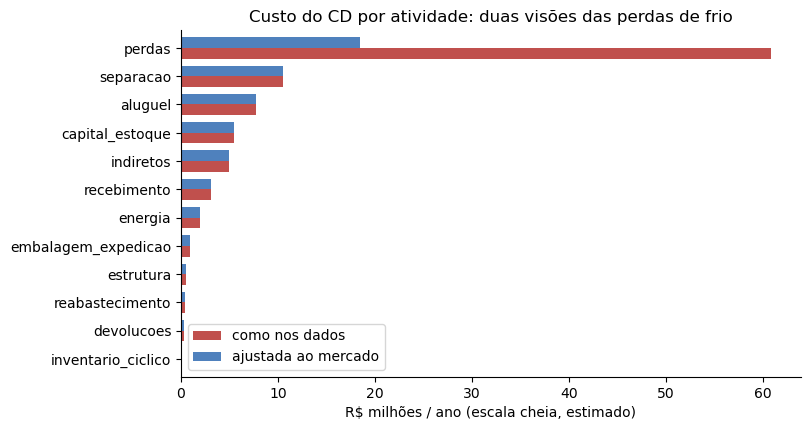

In [5]:
# Barras agrupadas: custo total por atividade nas duas visões (comparar duas séries na mesma categoria).
ativ = cts.drop(columns="total").sum()
ativ_m = ativ.copy(); ativ_m["perdas"] -= reducao_zona.sum()
tab = pd.DataFrame({"como nos dados": ativ, "ajustada ao mercado": ativ_m}).sort_values("como nos dados") / 1e6
fig, ax = plt.subplots(figsize=(8, 4.5))
tab.plot.barh(ax=ax, color=["#C0504D", "#4F81BD"], width=0.75)
ax.set_xlabel("R$ milhões / ano (escala cheia, estimado)"); ax.set_title("Custo do CD por atividade: duas visões das perdas de frio")
savefig(fig, "10a_linha_base_visoes", out=PH10)
print(f"Total: R$ {ativ.sum() / 1e6:,.1f} mi (dados) x R$ {ativ_m.sum() / 1e6:,.1f} mi (mercado)")

**Leitura:** mesmo na visão de mercado, as perdas continuam sendo um bloco grande do custo, mas deixam de
ser a maioria. A separação e o aluguel ganham peso relativo. Isso muda o **tamanho** do ganho do kit de
doca fria, mas não a conclusão de que ele vem primeiro (seção 4).

**Lacuna da linha de base:** o custeio da Fase 8 conta a **mão de obra** das devoluções, mas não o produto
devolvido e descartado (R$ ~9 mi/ano no Pareto da Fase 9). Ele fica fora do total para manter a base da
Fase 8 e é citado como exposição.

## 3. Separação: slotting e carrinho calculados juntos
Na Fase 8, slotting e carrinho foram medidos **cada um contra o cenário atual**. Somar os dois exagera,
porque o carrinho reduz a caminhada que o slotting também reduz. Aqui o mesmo modelo de horas da Fase 8
roda o cenário **combinado**, e a diferença vira um desconto de interação no carrinho.

In [6]:
def horas_sep(dist_col, lote_ecom):
    """Horas de separador e de retrátil no ano-base (escala cheia), mesmo modelo da 08b."""
    lin = fs.preparar_linhas(INI, FIM, slot, prm, dist_col)
    lin["grupo"] = np.where(lin.channel == "ECOM",
                            lin.zone + "-" + (lin.order_ts - pd.Timedelta(hours=prm["ecom_cutoff_h"])).dt.normalize().astype(str),
                            lin.order_id.astype(str) + "-" + lin.zone)
    sub = lin.groupby(["order_id", "zone"]).agg(channel=("channel", "first"), grupo=("grupo", "first"),
                                                 n=("sku_id", "size"), dist=("dist_rota", "max"),
                                                 pick=("pick_s", "sum"), ret=("retratil_s", "sum")).reset_index()
    # No e-commerce, a cada `lote_ecom` pedidos do mesmo grupo forma-se uma viagem (carrinho)
    sub["viagem"] = np.where(sub.channel == "ECOM",
                             sub.grupo + "-" + (sub.groupby("grupo").cumcount() // lote_ecom).astype(str), sub.grupo)
    g = sub.groupby(["viagem", "channel"]).agg(n=("n", "sum"), dist=("dist", "max"), pick=("pick", "sum"),
                                                ret=("ret", "sum")).reset_index()
    triagem = np.where((g.channel == "ECOM") & (lote_ecom > 1), P["picking_strategy"]["sort_time_per_line_s"] * g.n, 0)
    sep_h = (prm["tour_setup_s"] + 2 * g.dist / prm["walk"] + g.pick + triagem + g.ret).sum() / 3600 * K
    ret_h = g.ret.sum() / 3600 * K
    return sep_h * c_op + ret_h * c_ret            # custo anual em R$ (hora paga)

custo_sep = {"atual": horas_sep("dist_face_m", 1), "slotting": horas_sep("dist_otima", 1),
             "carrinho": horas_sep("dist_face_m", 8), "slotting + carrinho": horas_sep("dist_otima", 8)}
sep = pd.Series(custo_sep).to_frame("custo_R$")
sep["economia_R$"] = sep.loc["atual", "custo_R$"] - sep["custo_R$"]
ganho_slot = sep.loc["slotting", "economia_R$"]
ganho_cart_isolado = sep.loc["carrinho", "economia_R$"]
ganho_cart_incremental = sep.loc["slotting + carrinho", "economia_R$"] - ganho_slot
print(f"Soma dos isolados: R$ {ganho_slot + ganho_cart_isolado:,.0f} | combinado: "
      f"R$ {sep.loc['slotting + carrinho', 'economia_R$']:,.0f} | interação: "
      f"R$ {ganho_slot + ganho_cart_isolado - sep.loc['slotting + carrinho', 'economia_R$']:,.0f}")
sep.round(0)

Soma dos isolados: R$ 2,179,118 | combinado: R$ 2,153,121 | interação: R$ 25,998


,custo_R$,economia_R$
atual,"10,469,872.00",0.00
slotting,"9,516,931.00","952,940.00"
carrinho,"9,243,694.00","1,226,178.00"
slotting + carrinho,"8,316,751.00","2,153,121.00"


## 4. Valor-base de cada iniciativa (escala cheia, R$/ano em regime)
| Iniciativa | Como o valor-base foi obtido |
|---|---|
| I01 Kit de doca fria + POP | fração evitável (40%) da perda **crônica** de frio, nas duas visões |
| I02 Agendamento de docas | estadia de carretas da simulação (Fase 8) |
| I03 Slotting | recalculado na seção 3 |
| I04 Carrinho e-commerce | **incremental sobre o slotting** (seção 3) |
| I05 Reabastecimento por mínimo | Fase 5 × 10 (escala) × fator de hora paga |
| I06 Trava de vida útil 70% | fração evitável (80%) do vencimento de lotes aceitos < 70% (Pareto da Fase 9) |
| I07 +1 doca fria por câmara | estadia de carreta após o agendamento (Fase 8) |
| I08 Inventário cíclico ABC | custo adicional (Fase 9) |
| I09 ES/PP por SKU | custo de capital do estoque adicional (Fase 4 × taxa de 15% a.a.) |

In [7]:
reg = pd.read_csv(SAVINGS, sep=";", decimal=",", encoding="utf-8-sig")
cart8 = pd.read_csv(PH8 / "08b_carteira_investimentos.csv", sep=";", decimal=",").set_index("projeto")
pareto = pd.read_csv(PH9 / "09a_pareto_perdas.csv", sep=";", decimal=",").set_index("causa")
INI_CAT = CP["initiatives"]
moda = lambda tri: tri[1]                           # valor mais provável da triangular

# I05: Fase 5 em escala 10% e hora-padrão -> escala cheia e hora paga
reab_f5 = reg.loc[reg.acao.str.startswith("Reabastecimento por mínimo"), "brl_ano_estimado"].iloc[0]
# I09: capital adicional do estoque proposto na Fase 4 (por SKU, escala 10% -> cheia)
es = pd.read_csv(ROOT / "reports" / "phase4" / "sku_safety_stock_rop.csv", sep=";", decimal=",")
custo_unit = q("SELECT sku_id, unit_cost FROM dim_sku").set_index("sku_id").unit_cost
capital_extra = ((es.estoque_medio_proposto - es.estoque_medio_atual) * es.sku_id.map(custo_unit)).sum() * K
venc70 = pareto.loc["Vencimento: lote aceito < 70% de vida", "R$_ano"]

base = {
    "I01": {"dados": visoes.loc["Total", "cronica_dados_mi"] * 1e6 * moda(INI_CAT["I01"]["avoidable_share"]),
            "mercado": visoes.loc["Total", "cronica_mercado_mi"] * 1e6 * moda(INI_CAT["I01"]["avoidable_share"])},
    "I02": cart8.loc["Agendamento distribuído de docas", "beneficio_ano"],
    "I03": ganho_slot,
    "I04": ganho_cart_incremental,
    "I05": reab_f5 * K * FATOR_PAGO,
    "I06": venc70 * moda(INI_CAT["I06"]["avoidable_share"]),
    "I07": cart8.loc["+1 doca fria em cada câmara (após agendamento)", "beneficio_ano"],
    "I08": reg.loc[reg.acao.str.startswith("Programa de inventário cíclico"), "brl_ano_estimado"].iloc[0],
    "I09": -capital_extra * C["inventory_carrying_rate_year"],
}
inic = pd.DataFrame([{"id": k, "iniciativa": v["name"], "fonte": v["source"], "base_do_valor": v["basis"],
                      "valor_dados": (base[k]["dados"] if isinstance(base[k], dict) else base[k]),
                      "valor_mercado": (base[k]["mercado"] if isinstance(base[k], dict) else base[k]),
                      "capex": v["capex_brl"], "esforco": v["effort"], "risco": v["risk"],
                      "inicio_mes": v["go_live_month"], "rampa_meses": v["ramp_months"]}
                     for k, v in INI_CAT.items()])
inic["payback_meses_mercado"] = np.where(inic.valor_mercado > 0, 12 * inic.capex / inic.valor_mercado, np.nan)
save(inic.round(1), "10a_iniciativas_base", out=PH10)
print(f"Capital adicional em estoque (ES/PP por SKU): R$ {capital_extra / 1e6:,.2f} mi")
vis = inic[["id", "iniciativa", "valor_dados", "valor_mercado", "capex", "payback_meses_mercado"]].copy()
for c in ["valor_dados", "valor_mercado", "capex"]:
    vis[c] = (vis[c] / 1e3).round(0)
vis.rename(columns={"valor_dados": "R$ mil/ano (dados)", "valor_mercado": "R$ mil/ano (mercado)", "capex": "CAPEX (R$ mil)"})

Capital adicional em estoque (ES/PP por SKU): R$ 0.72 mi


,id,iniciativa,R$ mil/ano (dados),R$ mil/ano (mercado),CAPEX (R$ mil),payback_meses_mercado
0,I01,Kit de doca fria + POP-01 (8 docas),"14,136.00","2,998.00",760.00,3.04
1,I02,Agendamento distribuído de docas,952.00,952.00,0.00,0.00
2,I03,Slotting otimizado das faces (PuLP),953.00,953.00,25.00,0.31
3,I04,Carrinho multi-volume no e-commerce (lote de 8),"1,200.00","1,200.00",148.00,1.48
4,I05,Reabastecimento da face por mínimo (gatilho no...,"1,092.00","1,092.00",0.00,0.00
5,I06,Trava de vida útil de 70% no WMS + scorecard F...,"1,049.00","1,049.00",0.00,0.00
6,I07,+1 doca fria em cada câmara (após o agendamento),"1,827.00","1,827.00",760.00,4.99
7,I08,Inventário cíclico por ABC (POP-04),-120.00,-120.00,0.00,NaN
8,I09,Estoque de segurança e ponto de pedido por SKU,-108.00,-108.00,0.00,NaN


In [8]:
tot = inic[["valor_dados", "valor_mercado"]].sum()
print(f"Pipeline em regime (soma dos valores-base, sem incerteza): R$ {tot.valor_dados / 1e6:,.1f} mi/ano (dados) | "
      f"R$ {tot.valor_mercado / 1e6:,.1f} mi/ano (mercado) | CAPEX R$ {inic.capex.sum() / 1e6:,.2f} mi")
print(f"= {100 * tot.valor_dados / total_base:.0f}% da linha de base (dados) | "
      f"{100 * tot.valor_mercado / (total_base - reducao_zona.sum()):.0f}% da linha de base (mercado)")

Pipeline em regime (soma dos valores-base, sem incerteza): R$ 21.0 mi/ano (dados) | R$ 9.8 mi/ano (mercado) | CAPEX R$ 1.69 mi
= 22% da linha de base (dados) | 18% da linha de base (mercado)


## 5. Reconciliação com o `savings_register.csv`
Cada linha do registro das fases 5–9 recebe um destino: **usada** (entra no pipeline), **substituída**
(outra linha mede a mesma coisa melhor) ou **fora do total** (evitação de custo frente a uma alternativa,
ou sem valor em R$). Assim fica rastreável por que o total da Fase 10 não é a soma do registro.

In [9]:
destino = {
    "Slotting das faces por giro": ("I03", "substituída", "recalculada em escala cheia e hora paga (seção 3)"),
    "Reabastecimento por mínimo": ("I05", "usada", "× 10 (escala) × fator de hora paga"),
    "Slotting otimizado reduz temporários": ("I03", "fora do total", "as horas de pico já estão no ganho anual do slotting"),
    "Agendamento distribuído de docas (simulação)": ("I02", "substituída", "a Fase 8 valorou a espera em R$"),
    "Separação em lote do e-commerce": ("I04", "substituída", "Fase 8 a hora paga; aqui incremental sobre o slotting"),
    "Roteirização S-shape": ("—", "fora do total", "com slotting por popularidade o ganho de rota cai a ~0 (07a)"),
    "Quadro fixo + temporários": ("—", "fora do total", "evitação de custo frente a um quadro fixo para o pico; não reduz a base"),
    "Kit de doca fria": ("I01", "usada", "nas duas visões de perda de frio"),
    "+1 doca fria": ("I07", "usada", "já incremental ao agendamento"),
    "Carrinho multi-volume": ("I04", "substituída", "descontada a interação com o slotting"),
    "Agendamento distribuído de docas (investimento)": ("I02", "usada", "estadia de carreta (simulação)"),
    "Slotting otimizado (investimento)": ("I03", "substituída", "mesmo modelo, recalculado aqui"),
    "Programa de inventário cíclico": ("I08", "usada", "custo (valor negativo)"),
}
def achar(acao):
    for chave, d in destino.items():
        if acao.startswith(chave):
            return d
    return ("?", "sem destino", "")
reg[["iniciativa", "tratamento", "motivo"]] = pd.DataFrame([achar(a) for a in reg.acao], index=reg.index)
assert (reg.tratamento != "sem destino").all(), "toda linha do registro precisa de destino"
save(reg[["fase", "acao", "brl_ano_estimado", "iniciativa", "tratamento", "motivo"]], "10a_reconciliacao_registro", out=PH10)
print(f"Soma bruta do registro: R$ {reg.brl_ano_estimado.sum() / 1e6:,.1f} mi/ano (mistura escalas e conta o slotting 4 vezes)")
reg[["fase", "acao", "brl_ano_estimado", "iniciativa", "tratamento"]]

Soma bruta do registro: R$ 23.3 mi/ano (mistura escalas e conta o slotting 4 vezes)


,fase,acao,brl_ano_estimado,iniciativa,tratamento
0,5,Slotting das faces por giro (modelo PuLP),"91,499.00",I03,substituída
1,5,Reabastecimento por mínimo (face atende 85% da...,"88,157.00",I05,usada
2,6,Slotting otimizado reduz temporários no pico (...,"287,040.00",I03,fora do total
3,6,Agendamento distribuído de docas (simulação),0.00,I02,substituída
4,7,Separação em lote do e-commerce (carrinho de 8...,"930,996.00",I04,substituída
5,7,Roteirização S-shape/melhor rota no WMS (B2B s...,"49,836.00",—,fora do total
6,7,Quadro fixo + temporários (vs. fixo dimensiona...,"2,904,797.00",—,fora do total
7,8,Kit de doca fria + POP (8 docas) (investimento),"14,135,537.00",I01,usada
8,8,+1 doca fria em cada câmara (após agendamento)...,"1,826,955.00",I07,usada
9,8,Carrinho multi-volume no e-commerce (investime...,"1,226,178.00",I04,substituída


**Leitura:**
- A soma bruta do registro **não serve** como meta: mistura escala 10% com escala cheia, conta o slotting
  em quatro fases e inclui uma evitação de custo (quadro fixo × temporários) que não reduz a linha de base.
- O pipeline consolidado fica concentrado em poucas iniciativas. O kit de doca fria lidera nas duas visões,
  mas na visão de mercado ele deixa de ser "maior que todo o resto somado".
- Iniciativas **sem valor em R$** continuam no plano (10b) como habilitadoras: telemetria das câmaras
  (protege contra um evento de R$ ~20 mi), 8D com o Fornecedor 010 (recall), FEFO dirigido e POP-02.

**Conferência:** a linha de base fecha com o custeio da Fase 8 (R$ 96,7 mi) e as perdas de frio fecham com
o Pareto da Fase 9 (R$ 56,0 mi = 24,8 + 20,7 + 10,6).

In [10]:
assert abs(total_base - 96_663_696) / 96_663_696 < 0.001
assert abs(visoes.loc["Total", "frio_dados_mi"] - (pareto.loc[pareto.index.str.startswith("Frio"), "R$_ano"].sum() / 1e6)) < 0.1
log(NB, f"linha de base = 08a (R$ {total_base / 1e6:,.1f} mi); visão de mercado: frio a "
        f"{CP['market_cold_chain_loss_pct_revenue']}% da receita da zona; slotting+carrinho recalculados juntos "
        f"(interação descontada do carrinho); registro reconciliado em 10a_reconciliacao_registro.csv")